In [1]:
# Step 1: Import libraries and check environment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Setup successful!")

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Setup successful!


In [3]:
# Step 2: Load the House Prices dataset from OpenML

from sklearn.datasets import fetch_openml
import pandas as pd

housing = fetch_openml(
    name="house_prices",
    version=1,
    as_frame=True
)

df = housing.data.copy()
df["SalePrice"] = housing.target

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nRequired columns available:")
print([
    col for col in [
        "LotArea", "BedroomAbvGr", "FullBath",
        "GarageCars", "OverallQual", "YearBuilt",
        "SalePrice"
    ] if col in df.columns
])

print("\nTarget column: SalePrice")

Dataset loaded successfully!
Dataset shape: (1460, 81)

First 5 rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Required columns available:
['LotArea', 'BedroomAbvGr', 'FullBath', 'GarageCars', 'OverallQual', 'YearBuilt', 'SalePrice']

Target column: SalePrice


Data quality check

In [4]:
# Step 3: Check data quality

print("Dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values (top 20):")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(20)
)

print("\nData types:")
print(df.dtypes.value_counts())

print("\nSalePrice summary:")
display(df["SalePrice"].describe())

print("\nMissing target values:", df["SalePrice"].isnull().sum())

Dataset shape: (1460, 81)

Duplicate rows: 0

Missing values (top 20):


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageFinish,81
GarageQual,81
GarageYrBlt,81
GarageType,81



Data types:
object     43
int64      35
float64     3
Name: count, dtype: int64

SalePrice summary:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000



Missing target values: 0


Data cleaning

In [5]:
# Step 4: Data cleaning

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove the identifier column
df_clean = df_clean.drop(columns=["Id"], errors="ignore")

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Separate target and features
target = "SalePrice"
X = df_clean.drop(columns=[target])
y = df_clean[target]

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

print("Rows and columns:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing target values:", y.isna().sum())
print("Categorical features:", len(cat_cols))
print("Numerical features:", len(num_cols))
print("Total missing feature values:", X.isna().sum().sum())

Rows and columns: (1460, 80)
Duplicate rows: 0
Missing target values: 0
Categorical features: 43
Numerical features: 36
Total missing feature values: 6965


Train-Test split and preprocessing

In [6]:
# Step 5: Train-test split and preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df_clean.drop(columns="SalePrice")
y = df_clean["SalePrice"]

# Log-transform target to reduce right skew
y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(num_cols))
print("Categorical features:", len(cat_cols))
print("Preprocessing pipeline created successfully!")

Training rows: 1168
Testing rows: 292
Numeric features: 36
Categorical features: 43
Preprocessing pipeline created successfully!


Train and Evaluate Multiple ML Model

In [7]:
# Step 6: Train and evaluate regression models

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pred_log = pipeline.predict(X_test)

    # Convert predictions and targets back to house prices
    y_true = np.expm1(y_test)
    y_pred = np.maximum(0, np.expm1(pred_log))

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model by test RMSE:", best_model_name)

,Model,MAE,RMSE,R2
0,Linear Regression,14856.242,22729.526,0.933
1,Ridge Regression,16414.961,25059.467,0.918
2,Random Forest,17550.753,29943.512,0.883
3,Gradient Boosting,16922.491,30265.124,0.881


Best model by test RMSE: Linear Regression


Visualize model performance

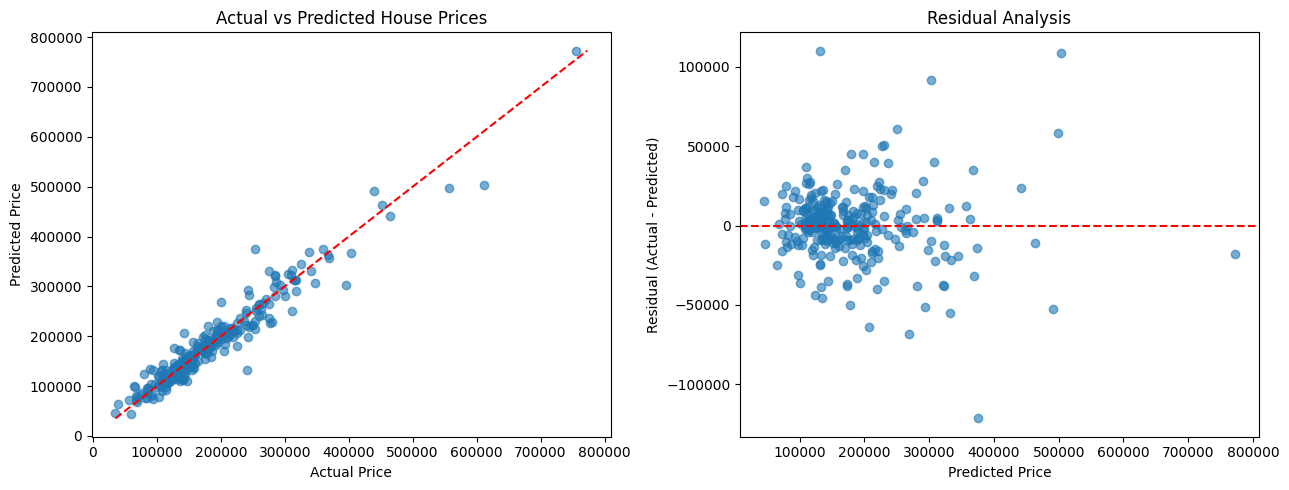

Mean absolute error: 14856.24
Mean residual: 322.8


In [8]:
# Step 7: Actual vs predicted prices and residual analysis

import matplotlib.pyplot as plt
import numpy as np

y_actual = np.expm1(y_test)
y_predicted = np.maximum(
    0, np.expm1(best_model.predict(X_test))
)
residuals = y_actual - y_predicted

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs predicted
axes[0].scatter(y_actual, y_predicted, alpha=0.6)
limits = [
    min(y_actual.min(), y_predicted.min()),
    max(y_actual.max(), y_predicted.max())
]
axes[0].plot(limits, limits, "r--")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Actual vs Predicted House Prices")

# Residuals
axes[1].scatter(y_predicted, residuals, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Analysis")

plt.tight_layout()
plt.show()

print("Mean absolute error:", round(np.mean(np.abs(residuals)), 2))
print("Mean residual:", round(np.mean(residuals), 2))

EDA

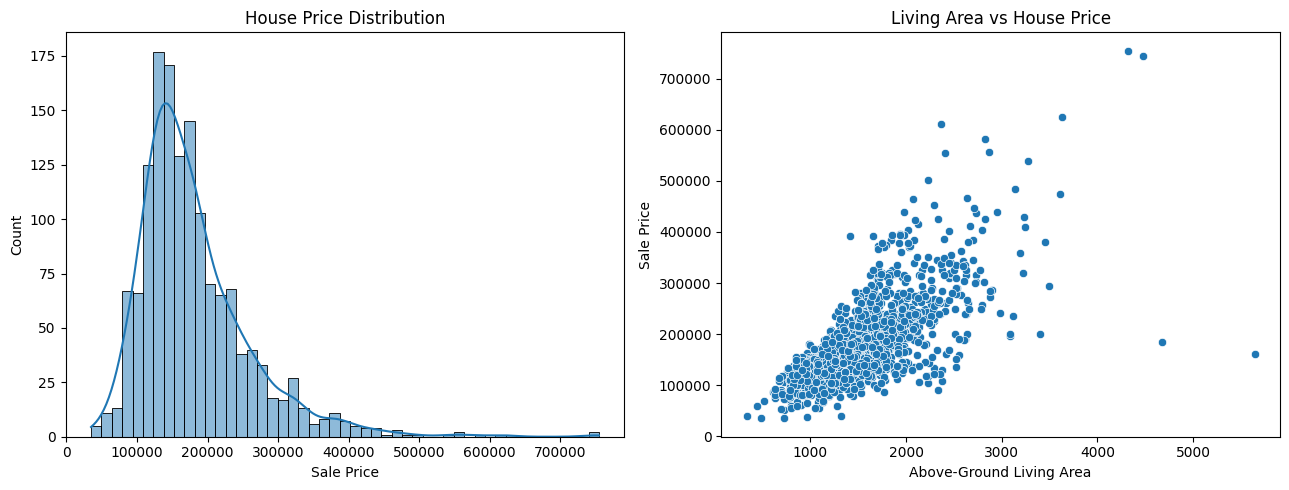

Top 10 numerical features correlated with SalePrice:


,Correlation
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


In [9]:
# Step 8: EDA — price distribution and feature relationships

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("House Price Distribution")
axes[0].set_xlabel("Sale Price")

sns.scatterplot(
    data=df_clean, x="GrLivArea", y="SalePrice", ax=axes[1]
)
axes[1].set_title("Living Area vs House Price")
axes[1].set_xlabel("Above-Ground Living Area")
axes[1].set_ylabel("Sale Price")

plt.tight_layout()
plt.show()

# Strongest numerical correlations with SalePrice
correlations = (
    df_clean.select_dtypes(include="number")
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=abs, ascending=False)
)

print("Top 10 numerical features correlated with SalePrice:")
display(correlations.head(10).to_frame("Correlation").round(3))

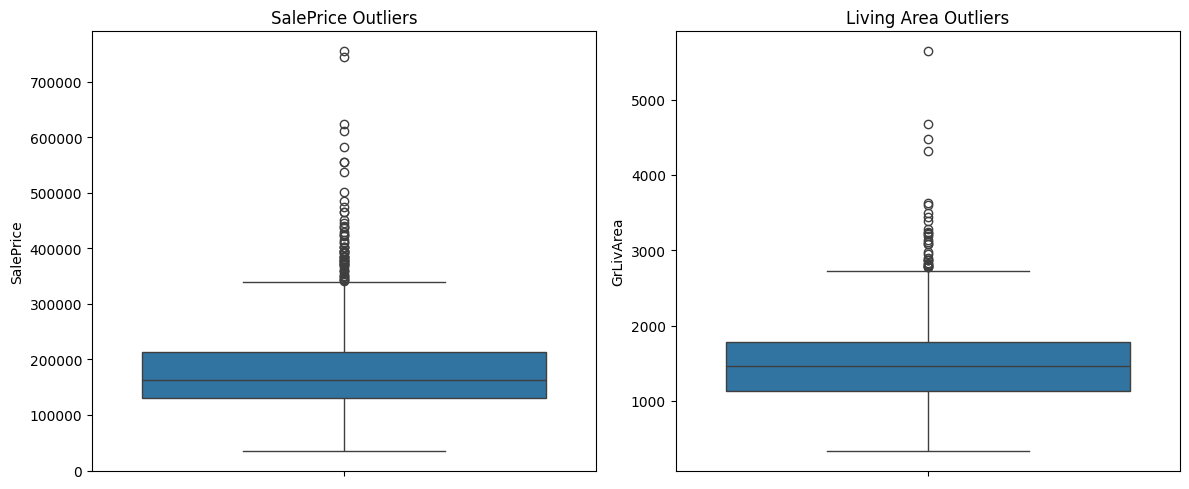

SalePrice: 61 potential outliers
GrLivArea: 31 potential outliers


In [10]:
# Step 9: Outlier analysis

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_clean["SalePrice"], ax=axes[0])
axes[0].set_title("SalePrice Outliers")

sns.boxplot(y=df_clean["GrLivArea"], ax=axes[1])
axes[1].set_title("Living Area Outliers")

plt.tight_layout()
plt.show()

# IQR-based outlier counts (diagnostic only)
for col in ["SalePrice", "GrLivArea"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df_clean[col] < lower) |
             (df_clean[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

Fold Cross valiadation

In [11]:
# Step 10: 5-fold cross-validation

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, mean_squared_error

def rmse_original(y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.maximum(0, np.expm1(y_pred_log))
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(
    rmse_original,
    greater_is_better=False
)

cv_results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=rmse_scorer,
        n_jobs=-1
    )

    fold_rmse = -scores["test_score"]

    cv_results.append({
        "Model": name,
        "Mean CV RMSE": fold_rmse.mean(),
        "Std CV RMSE": fold_rmse.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values("Mean CV RMSE")
display(cv_df.round(2))

print("Best model by 5-fold CV:", cv_df.iloc[0]["Model"])

,Model,Mean CV RMSE,Std CV RMSE
3,Gradient Boosting,28864.13,4664.90
2,Random Forest,30720.83,4552.78
1,Ridge Regression,44748.18,31714.22
0,Linear Regression,52250.06,39667.97


Best model by 5-fold CV: Gradient Boosting


Model evaluation

In [12]:
# Step 11: Final model evaluation

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_model_name = "Gradient Boosting"

best_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models[best_model_name]))
])

best_model.fit(X_train, y_train)

y_actual = np.expm1(y_test)
y_predicted = np.maximum(0, np.expm1(best_model.predict(X_test)))

final_mae = mean_absolute_error(y_actual, y_predicted)
final_rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))
final_r2 = r2_score(y_actual, y_predicted)

print("Final model:", best_model_name)
print(f"Test MAE:  {final_mae:.2f}")
print(f"Test RMSE: {final_rmse:.2f}")
print(f"Test R²:   {final_r2:.4f}")

Final model: Gradient Boosting
Test MAE:  16922.49
Test RMSE: 30265.12
Test R²:   0.8806


save trained model

In [13]:
# Step 12: Save the trained model

import joblib
import json

joblib.dump(best_model, "house_price_model.pkl")

metrics = {
    "model": best_model_name,
    "MAE": float(final_mae),
    "RMSE": float(final_rmse),
    "R2": float(final_r2)
}

with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Model saved: house_price_model.pkl")
print("Metrics saved: model_metrics.json")

Model saved: house_price_model.pkl
Metrics saved: model_metrics.json


Test sample prediction

In [14]:
# Step 13: Verify saved model and predict one test example

import joblib
import numpy as np

loaded_model = joblib.load("house_price_model.pkl")

sample_house = X_test.iloc[[0]]
actual_price = float(np.expm1(y_test.iloc[0]))
predicted_price = max(
    0.0, float(np.expm1(loaded_model.predict(sample_house)[0]))
)

print(f"Actual house price:    ${actual_price:,.2f}")
print(f"Predicted house price: ${predicted_price:,.2f}")
print(f"Absolute error:        ${abs(actual_price-predicted_price):,.2f}")
print("Model reload and prediction successful!")

Actual house price:    $154,500.00
Predicted house price: $142,549.85
Absolute error:        $11,950.15
Model reload and prediction successful!


Top 15 important features:


,Feature,Importance
3,num__OverallQual,0.4423
15,num__GrLivArea,0.1789
11,num__TotalBsmtSF,0.0458
246,cat__GarageFinish_Unf,0.0426
25,num__GarageCars,0.0396
5,num__YearBuilt,0.0306
8,num__BsmtFinSF1,0.0270
26,num__GarageArea,0.0250
6,num__YearRemodAdd,0.0242
2,num__LotArea,0.0192


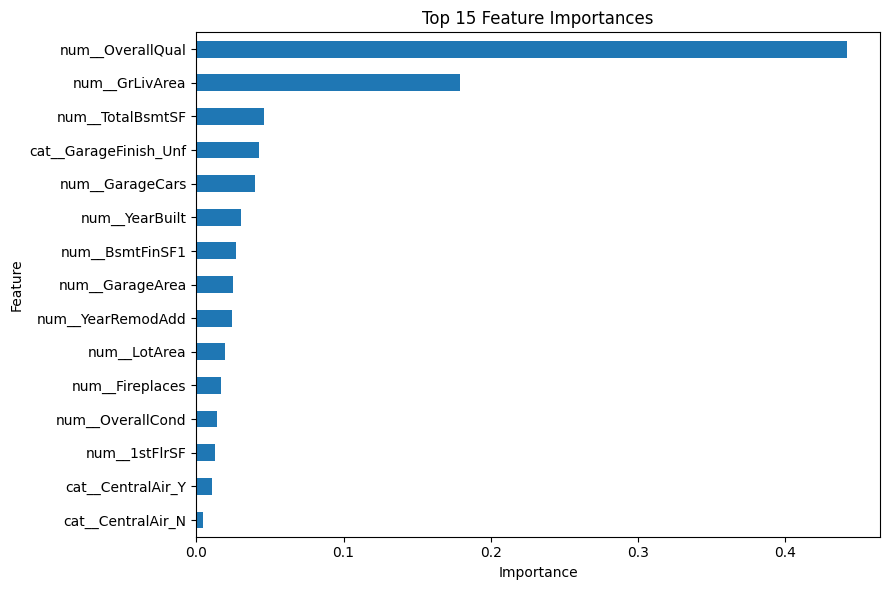

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

preprocessor_fitted = best_model.named_steps["preprocessor"]
model_fitted = best_model.named_steps["model"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model_fitted.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 important features:")
display(importance_df.head(15).round(4))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature", y="Importance",
    kind="barh", legend=False, figsize=(9, 6)
)
plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [17]:
# Step 15: Package the completed project

import os
import json
import zipfile
import pandas as pd

# Export evaluation tables
results_df.to_csv("model_comparison.csv", index=False)
cv_df.to_csv("cross_validation_results.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

# Save final evaluation metrics
with open("model_metrics.json", "w") as f:
    json.dump({
        "best_model": best_model_name,
        "test_MAE": float(final_mae),
        "test_RMSE": float(final_rmse),
        "test_R2": float(final_r2)
    }, f, indent=4)

# Create project README
readme = """
# House Price Prediction Using Machine Learning

## Overview
A regression project predicting house sale prices using property
characteristics from the Ames Housing dataset.

## Objectives
- Explore and clean housing data.
- Handle missing values with preprocessing pipelines.
- Encode categorical features and scale numerical features.
- Compare four regression algorithms.
- Evaluate predictions using MAE, RMSE and R-squared.
- Analyze feature importance.

## Dataset
- Source: OpenML, house_prices, version 1
- Original dataset: 1,460 rows and 81 columns
- Target: SalePrice
- Identifier column removed before modeling.

## Models Compared
- Linear Regression
- Ridge Regression
- Random Forest Regressor
- Gradient Boosting Regressor

## Model Selection
Gradient Boosting was selected based on the lowest mean
5-fold cross-validation RMSE.

## Held-out Test Results
- MAE: 16,922.49
- RMSE: 30,265.12
- R-squared: 0.8806

Errors are expressed in the dataset's price units (USD).

## Important Features
OverallQual and GrLivArea ranked highly in the model's
feature-importance analysis. Feature importance does not
imply causation.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn,
Google Colab and Joblib.

## Files
- House price prediction notebook (.ipynb)
- house_price_model.pkl
- model_metrics.json
- model_comparison.csv
- cross_validation_results.csv
- feature_importance.csv

## Limitations
Performance is based on one train/test split and cross-validation
on the training set. Results may not generalize to other markets
or current property prices. The model is an educational project,
not a professional property valuation.

## Reproducibility
The notebook contains the data loading, preprocessing,
training and evaluation workflow. The saved model includes
the preprocessing pipeline.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip() + "\n")

# Package project files
project_files = [
    "README.md",
    "house_price_model.pkl",
    "model_metrics.json",
    "model_comparison.csv",
    "cross_validation_results.csv",
    "feature_importance.csv"
]

missing = [name for name in project_files if not os.path.exists(name)]
if missing:
    raise FileNotFoundError(f"Missing project files: {missing}")

with zipfile.ZipFile(
    "House_Price_Prediction_Project.zip", "w",
    zipfile.ZIP_DEFLATED
) as z:
    for name in project_files:
        z.write(name)

print("Project package created successfully!")
print("Files included:", len(project_files))
print("ZIP: House_Price_Prediction_Project.zip")

from google.colab import files
files.download("House_Price_Prediction_Project.zip")

Project package created successfully!
Files included: 6
ZIP: House_Price_Prediction_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>